# Risk-Constrained Monte Carlo Portfolio Simulation and Optimization Using NSE Equities and Gold

This project models long-term investment outcomes using Monte Carlo simulations, with real National Stock Exchange (NSE) stock data. It quantifies goal-achievement probabilities and risk metrics aligned with portfolio management concepts.

We are using aggressive weighing to get the weights of the 3 types of assets which comprise the portfolio that we'll be analyzing. 

90% equity, 10% gold

This project will gauge this strategy's suitability for long-term wealth generation and will also use the Modern Portfolio Theory to come up with the ideal weights of different assets to maximize the Sharpe ratio.

| Ticker     | Weight |
| ---------- | ------ |
| RELIANCE   | 18%    |
| INFY       | 18%    |
| HDFCBANK   | 18%    |
| TATAMOTORS | 18%    |
| ITC        | 18%    |
| GOLDBEES   | 10%    |

These are widely traded, large-cap stocks, perfect for modeling realistic returns, volatility, and correlations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf
np.random.seed(42)  # Ensures reproducibility across runs

In [2]:
# Defining a dictionary
ticker_to_file = {'INFY': 'INFY.csv', 'RELIANCE': 'RELIANCE.csv', 'HDFCBANK': 'HDFCBANK.csv', 'ITC': 'ITC.csv', 'TATAMOTORS': 'TATAMOTORS.csv','GOLDBEES': 'GOLDBEES.csv'}

price_data = {}

for ticker, filename in ticker_to_file.items():        # Iterating through the defined dictionary
    try:                                   # try-catch block has been created; attempts to execute the code within the try block. If an error occurs, it "catches" the error and executes the code within the except block instead of crashing the program
        df = pd.read_csv(filename)
        df.columns = df.columns.str.strip()  # Clean column names-> removes any leading or trailing whitespace from each column name
        print(f"✅ {filename} loaded: {df.columns.tolist()}")
    except Exception as e:
        print(f"❌ {filename} load failed: {e}")
        continue

    # Confirming 'Date' column exists
    if 'Date' not in df.columns:
        print(f"❌ No 'Date' column in {filename}")
        continue

    # Parsing dates
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    # pd.to_datetime is a ver strong Pandas  function that attempts to convert the values in the column into date-time objects
    # errors='coerce' - > If pd.to_datetime encounters any value in the 'Date' column that it cannot parse into a valid date and time format, it will replace that value with NaT (Not a Time)
    df.dropna(subset=['Date'], inplace=True)   # Removes rows or columns that are NaN or NaT
    df.drop_duplicates(subset='Date', keep='first', inplace=True)  # Drops rows with the same Date entry, keeps only the first one
    df.set_index('Date', inplace=True)

    # Clean all object columns (likely numeric values in string format)
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.replace(',', '').str.replace('"', '')
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Drop rows with NaN in 'Close'
    if 'Close' not in df.columns:
        print(f"❌ No 'Close' column in {filename}")
        continue
    df.dropna(subset=['Close'], inplace=True)

    price_data[ticker] = df['Close']

# Combine all Close prices into one DataFrame
if price_data:
    prices = pd.concat(price_data.values(), axis=1)
    prices.columns = list(price_data.keys())
    prices.dropna(inplace=True)
    print("\nFinal Combined price Dataframe:")
    print(prices.head())

✅ INFY.csv loaded: ['Date', 'Close', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']
✅ RELIANCE.csv loaded: ['Date', 'Close']
✅ HDFCBANK.csv loaded: ['Date', 'Close']


C:\Users\videh\AppData\Local\Temp\ipykernel_393392\895818609.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
C:\Users\videh\AppData\Local\Temp\ipykernel_393392\895818609.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
C:\Users\videh\AppData\Local\Temp\ipykernel_393392\895818609.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
C:\Users\videh\AppData\Local\Temp\ipykernel_393392\895818609.py:21:

✅ ITC.csv loaded: ['Date', 'Close']
✅ TATAMOTORS.csv loaded: ['Date', 'Close']
✅ GOLDBEES.csv loaded: ['Date', 'Close']

Final Combined price Dataframe:
               INFY  RELIANCE  HDFCBANK     ITC  TATAMOTORS  GOLDBEES
Date                                                                 
2024-12-31  1880.00   1215.45   1772.85  483.65      740.15     64.09
2024-12-30  1906.00   1210.70   1777.90  477.00      733.65     64.00
2024-12-27  1916.75   1221.05   1798.25  478.60      750.50     64.21
2024-12-26  1907.40   1216.55   1790.75  476.95      740.80     64.00
2024-12-24  1909.05   1222.75   1798.10  478.45      736.10     63.68


C:\Users\videh\AppData\Local\Temp\ipykernel_393392\895818609.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
C:\Users\videh\AppData\Local\Temp\ipykernel_393392\895818609.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


Computing daily log returns:

In [3]:
print(prices.dtypes)

INFY          float64
RELIANCE      float64
HDFCBANK      float64
ITC           float64
TATAMOTORS    float64
GOLDBEES      float64
dtype: object


In [4]:
prices

,INFY,RELIANCE,HDFCBANK,ITC,TATAMOTORS,GOLDBEES
Date,,,,,,
2024-12-31,1880.00,1215.45,1772.85,483.65,740.15,64.09
2024-12-30,1906.00,1210.70,1777.90,477.00,733.65,64.00
2024-12-27,1916.75,1221.05,1798.25,478.60,750.50,64.21
2024-12-26,1907.40,1216.55,1790.75,476.95,740.80,64.00
2024-12-24,1909.05,1222.75,1798.10,478.45,736.10,63.68
...,...,...,...,...,...,...
2015-01-07,1963.55,854.30,945.00,353.55,493.85,2502.20
2015-01-06,1954.20,836.10,942.25,360.25,501.40,2497.90
2015-01-05,1995.90,875.85,957.15,369.75,523.80,2466.20


Logarithmic returns are highly favored in Monte Carlo simulations for financial modeling primarily due to their additive property over time and their alignment with commonstatistical assumptions about asset prices. When simulating price paths over multiple periods (e.g., days, weeks), simply summing logarithmic returns directly gives the total log return for the entire period, which simplifies computations significantly compared to the multiplicative nature of simple returns. This additivity is crucial for efficiently projecting future price levels. This approach also ensures that simulated prices will never fall below zero, a realistic and essential constraint for financial assets, which might not always be guaranteed when directly modeling simple returns without careful handling. Finally, the symmetry of log returns around zero, where a gain and an equivalent loss have roughly equal but opposite log values, is a statistically desirable property that simplifies the analysis and interpretation of simulated outcomes.

In [5]:
returns = np.log(prices / prices.shift(1)).dropna()  # prices.shift(1) shifts prices down by 1 row (so that we can get the ratio to obtain returns -> prices/prices-shaofted)
display(returns.head())

,INFY,RELIANCE,HDFCBANK,ITC,TATAMOTORS,GOLDBEES
Date,,,,,,
2024-12-30,0.013735,-0.003916,0.002844,-0.013845,-0.008821,-0.001405
2024-12-27,0.005624,0.008512,0.011381,0.003349,0.022708,0.003276
2024-12-26,-0.004890,-0.003692,-0.004179,-0.003454,-0.013009,-0.003276
2024-12-24,0.000865,0.005083,0.004096,0.003140,-0.006365,-0.005013
2024-12-23,0.007957,-0.000368,0.001612,-0.008817,-0.019064,0.004544


In [6]:
# Portfolio weights
weights = np.array([0.18, 0.18, 0.18, 0.18, 0.18, 0.1])

assert len(weights) == len(returns.columns), "Weights and tickers must match"
assert np.isclose(weights.sum(), 1.0), "Weights must sum to 1"

In [7]:
# Running the Monte Carlo simulation

num_simulations = 15000
num_days = 252  # 1 year

mean_returns = returns.mean()     #  Calculating the mean daily logarithmic return for each asset in the portfolio based on historical data
cov_estimator = LedoitWolf()
cov_matrix = cov_estimator.fit(returns).covariance_

simulated_portfolio_values = np.zeros(num_simulations)

for i in range(num_simulations):
    simulated_returns = np.random.multivariate_normal(mean_returns, cov_matrix, num_days)
    cumulative_log_return = simulated_returns @ weights     # Does a matrix multiplication or dot product of the simulated log returns of assets and their weights described earlier
    cumulative_return = np.exp(np.sum(cumulative_log_return)) - 1   # Converts the sum of daily logarithmic returns into a single, total percentage return for the num_days period; -1 converts the growth factor into a percentage value -> 1.1-1=0.1=10%
    simulated_portfolio_values[i] = cumulative_return  #Stores the cumulatove returns for each simulation

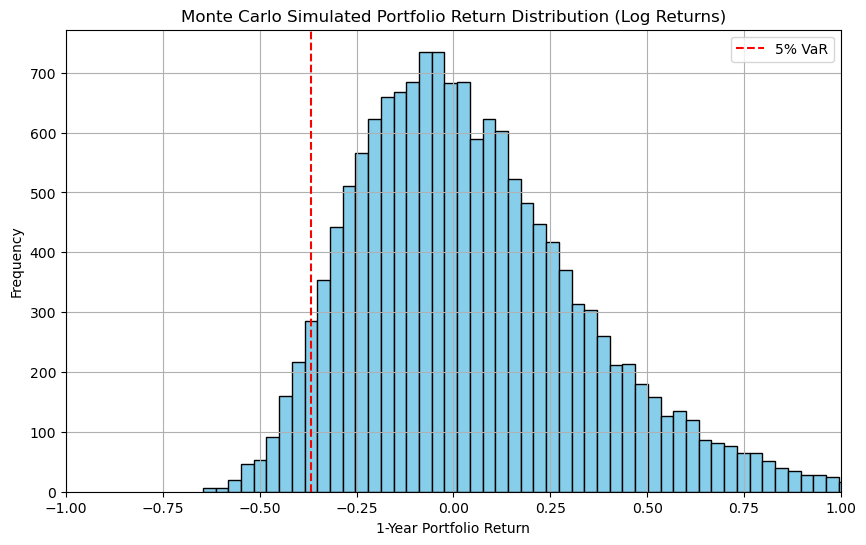

In [8]:
# Visualizing the distribution

plt.figure(figsize=(10, 6))
plt.hist(simulated_portfolio_values, bins=100, color='skyblue', edgecolor='black')
plt.axvline(np.percentile(simulated_portfolio_values, 5), color='red', linestyle='--', label='5% VaR') # Draws a vertical line at VaR
plt.xlim(-1, 1)
plt.title("Monte Carlo Simulated Portfolio Return Distribution (Log Returns)")
plt.xlabel("1-Year Portfolio Return")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)   # Adds a grid to the figure background
plt.show()

In [9]:
# Value at Risk (VaR) and mean

var_95 = np.percentile(simulated_portfolio_values, 5)  # There's only a 5% chance that the portfolio value falls below this level
mean_return = simulated_portfolio_values.mean()

print(f"📉 5% Value at Risk (VaR): {var_95:.2%}")
print(f"📈 Expected Return (Mean): {mean_return:.2%}")

📉 5% Value at Risk (VaR): -36.71%
📈 Expected Return (Mean): 5.04%


Visualizing 10 different paths of portfolio growth and their median over 1 year (252 days):

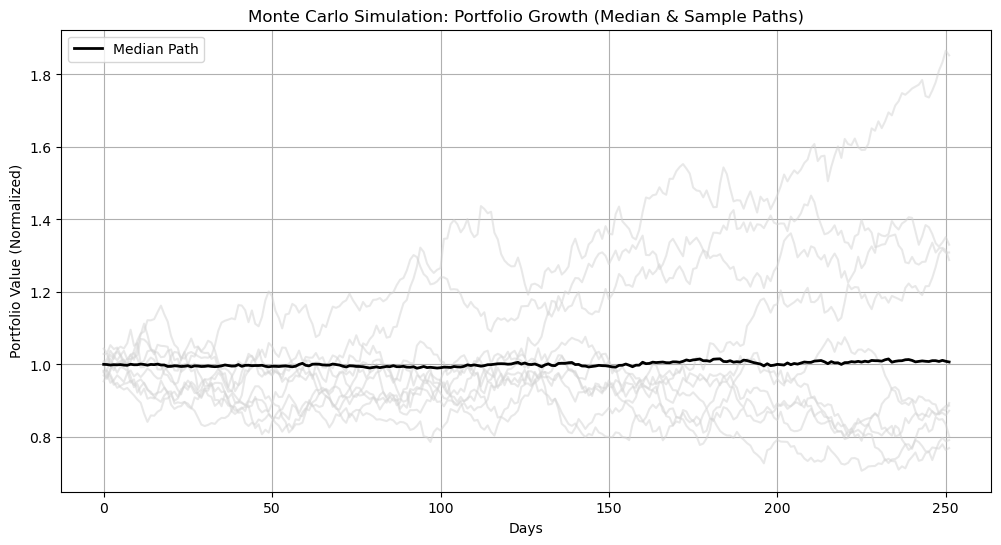

In [10]:
all_paths = []

for i in range(1000):
    simulated_returns = np.random.multivariate_normal(mean_returns, cov_matrix, num_days)
    portfolio_returns = simulated_returns @ weights
    portfolio_growth = np.exp(np.cumsum(portfolio_returns))
    all_paths.append(portfolio_growth)

all_paths = np.array(all_paths)
median_path = np.median(all_paths, axis=0)

# Plotting 10 sample paths + median
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.plot(all_paths[i], color='lightgray', alpha=0.5)
plt.plot(median_path, color='black', linewidth=2, label='Median Path')
plt.title("Monte Carlo Simulation: Portfolio Growth (Median & Sample Paths)")
plt.xlabel("Days")
plt.ylabel("Portfolio Value (Normalized)")
plt.legend()
plt.grid(True)
plt.show()

As we start optimising weights in the next cell, we've introduced weight constraints as well.

Weight constraints are essential in portfolio optimization to ensure realism, diversification, and regulatory alignment. Without constraints, an optimizer may allocate excessively to a single asset—sometimes over 90%—if it appears to maximize Sharpe ratio based on historical data, leading to concentrated, high-risk portfolios that are impractical in real-world investing. Constraints such as limiting any single asset to a maximum of 40% and a minimum of 5% enforce diversification, reduce overfitting to noisy historical returns, and reflect common regulatory or institutional guidelines. These bounds help generate portfolios that are not only theoretically optimal but also implementable, balanced, and robust under varying market conditions.

In [11]:
# Monte Carlo Optimisation

num_portfolios = 15000
results = np.zeros((num_portfolios, 3))
all_weights = []

for _ in range(num_portfolios):
    w = np.random.random(len(returns.columns))  # Generates an initial set of random weights
    w /= np.sum(w)
    if np.any(w > 0.4) or np.any(w < 0.05):
        continue
    all_weights.append(w)
    p_ret = np.sum(w * mean_returns) * 252     # Calculating the annualized expected return of the current random portfolio
    p_std = np.sqrt(w.T @ cov_matrix @ w) * np.sqrt(252)  # Calculates the annualized expected volatility (standard deviation) of the current random portfolio --> a measure of the portfolio's risk
    risk_free_rate = 0.0605              # Assuming 6.05% annual risk-free return (SBI 10 year FD rate)
    sharpe = (p_ret - risk_free_rate) / p_std
    results[_] = [p_ret, p_std, sharpe]

results_df = pd.DataFrame(results, columns=['Return', 'Volatility', 'Sharpe'])
weights_df = pd.DataFrame(all_weights, columns=returns.columns)
final_df = pd.concat([results_df, weights_df], axis=1)

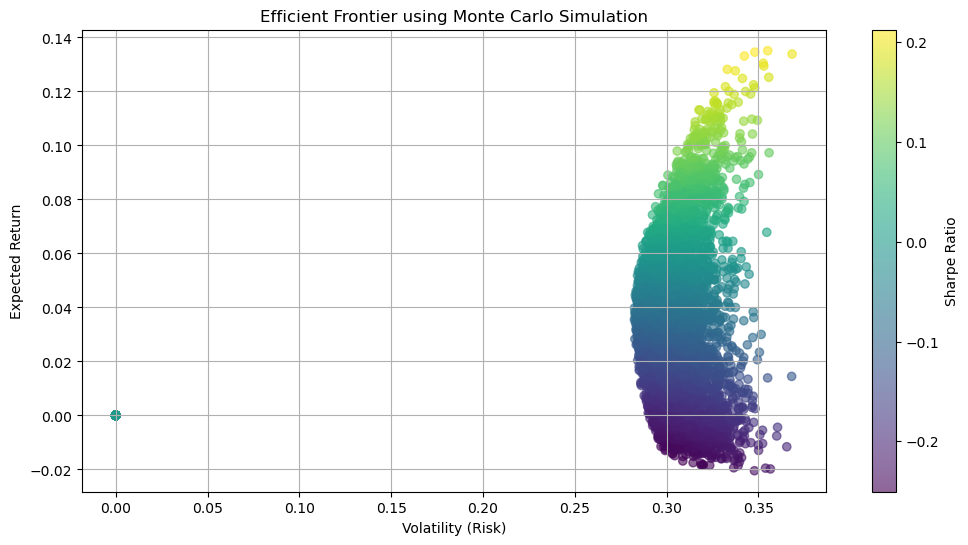

In [12]:
# Plotting Efficient Frontier

plt.figure(figsize=(12, 6))
scatter = plt.scatter(final_df['Volatility'], final_df['Return'], c=final_df['Sharpe'], cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label='Sharpe Ratio')
plt.xlabel('Volatility (Risk)')
plt.ylabel('Expected Return')
plt.title('Efficient Frontier using Monte Carlo Simulation')
plt.grid(True)
plt.show()

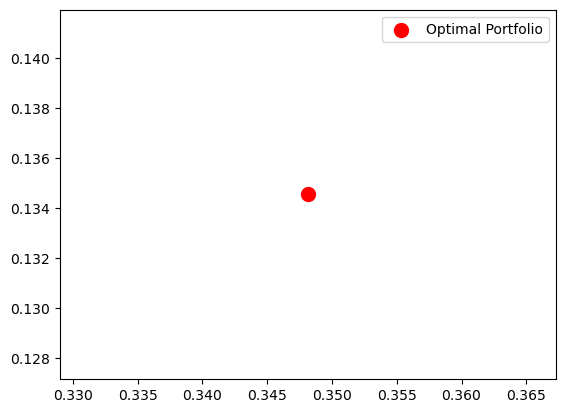

In [13]:
# Mark optimal portfolio

max_sharpe_idx = final_df['Sharpe'].idxmax()
opt_port = final_df.loc[max_sharpe_idx]
plt.scatter(opt_port['Volatility'], opt_port['Return'], color='red', s=100, label='Optimal Portfolio')
plt.legend()
plt.show()

In [14]:
print("Optimal Portfolio Allocation:")
for asset in returns.columns:
    print(f"{asset}: {opt_port[asset]*100:.2f}%")

print(f"📈 Expected Return: {opt_port['Return']:.2%}")
print(f"📉 Volatility: {opt_port['Volatility']:.2%}")
print(f"⚖️ Sharpe Ratio: {opt_port['Sharpe']:.2f}")

Optimal Portfolio Allocation:
INFY: 11.53%
RELIANCE: 12.12%
HDFCBANK: 20.60%
ITC: 16.84%
TATAMOTORS: 15.83%
GOLDBEES: 23.07%
📈 Expected Return: 13.45%
📉 Volatility: 34.81%
⚖️ Sharpe Ratio: 0.21
